# (1)-Introduction & Dataset

**SRGAN:Super Resolution Generative Adversarial Network**  
Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network

---
**Project Objective**

The primary objective of this project is to reconstruct high-resolution images from low-resolution inputs with photo-realistic details. This is achieved through a continuous adversarial game (Minimax Game) between The two neural networks

**System Architecture**
This project relies on two competing networks (GAN framework):
1. **The Generator:** A network based on Residual Blocks, tasked with upscaling the image by 4x and generating highly detailed, realistic textures.
* **The Generator:** Aims to produce highly detailed and realistic images that are convincing enough to **fool the Discriminator**.

2. **The Discriminator:** A classification network tasked with distinguishing between real high-quality images (Real HR) and the generated ones (Fake HR).

* **The Discriminator:** Acts as an expert detective, continuously improving its ability to distinguish between real high-resolution photographs and the "fake" ones produced by the Generator.

**The Secret to Success (Perceptual Loss)**
The core innovation behind SRGAN is abandoning the sole reliance on pixel-wise comparison (MSE Loss), which often produces "blurry" results. Instead, we use **Perceptual Loss**, which consists of:
* **VGG (Feature) Loss:** Ensures the matching of deep features and fine image details rather than just superficial colors.
* **Adversarial Loss:** Forces the generator to produce images that trick the human eye (and the discriminator) into believing they are real photographs.

---
**Dataset**  
This model is trained using the **DIV2K** dataset, which is one of the most famous and robust datasets used globally for Super-Resolution benchmarks.

---

**Training Plan in this Notebook:**
1. **Warm-up Phase:** Pre-training the generator alone initially (using MSE loss) to help it learn basic upscaling.
2. **Adversarial Training:** Running both networks together to push the image quality and high-frequency details to the maximum.

---


In [ ]:
import os
import matplotlib.pyplot as plt
import torch
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from IPython.display import Image as IPImage, display
import numpy as np
from torchvision.utils import save_image
import shutil
from torch.utils.data import Dataset, DataLoader
from torch import nn, optim
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
import torchvision.models as models
from torchvision.models import vgg19
import cv2

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!unzip -q "/content/drive/MyDrive/Colab Notebooks/dl_project/archive.zip" -d /content/

In [ ]:
!find /content/DIV2K_train_HR -maxdepth 3 -type f | head

/content/DIV2K_train_HR/DIV2K_train_HR/0029.png
/content/DIV2K_train_HR/DIV2K_train_HR/0493.png
/content/DIV2K_train_HR/DIV2K_train_HR/0605.png
/content/DIV2K_train_HR/DIV2K_train_HR/0393.png
/content/DIV2K_train_HR/DIV2K_train_HR/0608.png
/content/DIV2K_train_HR/DIV2K_train_HR/0588.png
/content/DIV2K_train_HR/DIV2K_train_HR/0191.png
/content/DIV2K_train_HR/DIV2K_train_HR/0126.png
/content/DIV2K_train_HR/DIV2K_train_HR/0012.png
/content/DIV2K_train_HR/DIV2K_train_HR/0330.png


In [ ]:
train_path = "/content/DIV2K_train_HR/DIV2K_train_HR"
valid_path = "/content/DIV2K_valid_HR/DIV2K_valid_HR"


train_images = sorted(os.listdir(train_path))
valid_images = sorted(os.listdir(valid_path))

print("Train:", len(train_images))
print("Valid:", len(valid_images))
print(train_images[:5])
print(valid_images[:5])

Train: 800
Valid: 100
['0001.png', '0002.png', '0003.png', '0004.png', '0005.png']
['0801.png', '0802.png', '0803.png', '0804.png', '0805.png']


(2040, 1404)


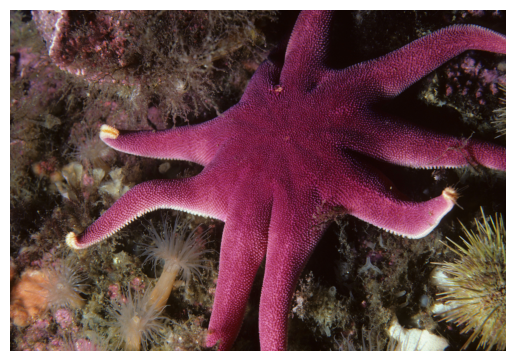

In [ ]:
img_path = os.path.join(train_path, train_images[0])
img = Image.open(img_path).convert("RGB")

print(img.size)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
folders = ['test_images','saved','srgan_mse_val','esrgan_l1_val','srgan_val','esrgan_val','inference_images','LR_inference_images','SRGAN_inference_images','ESRGAN_inference_images','MSE_inference_images','Full_SRGAN_inference_images']
for folder in folders:
    if not os.path.exists(folder):
        os.makedirs(folder)
        print(f"Folder '{folder}' created successfully.")
        print("="*40)
    else:
        print(f"Folder '{folder}' already exists.")
        print("="*40)


Folder 'test_images' already exists.
Folder 'saved' already exists.
Folder 'srgan_mse_val' already exists.
Folder 'esrgan_l1_val' already exists.
Folder 'srgan_val' already exists.
Folder 'esrgan_val' already exists.
Folder 'inference_images' already exists.
Folder 'LR_inference_images' already exists.
Folder 'SRGAN_inference_images' already exists.
Folder 'ESRGAN_inference_images' already exists.
Folder 'MSE_inference_images' already exists.
Folder 'Full_SRGAN_inference_images' created successfully.


# (2)-MODEL 1 : SRGAN

## 2.1-Config

In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LOAD_MODEL = True
SAVE_MODEL = True

CHECKPOINT_GEN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen.pth.tar"
CHECKPOINT_DISC = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/disc.pth.tar"

LEARNING_RATE = 1e-4
NUM_EPOCHS = 200
BATCH_SIZE = 16
NUM_WORKERS = 2
HIGH_RES = 96
LOW_RES = HIGH_RES // 4
IMG_CHANNELS = 3


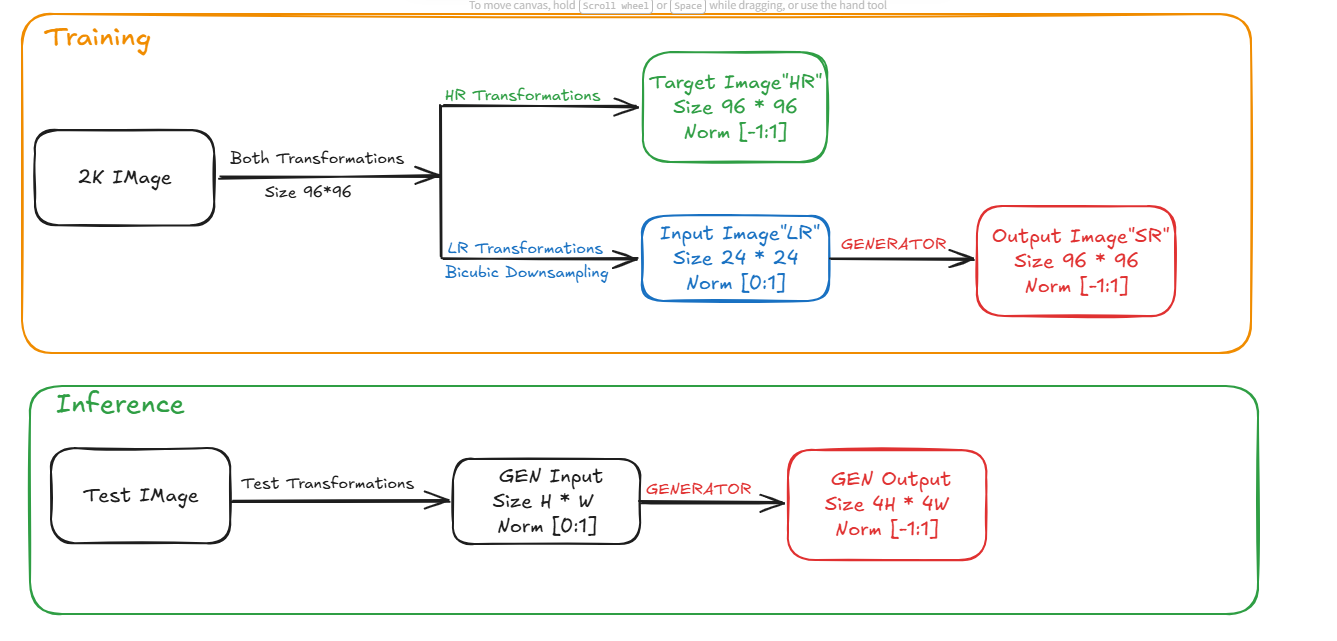

In [ ]:
display(IPImage("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/images/Image Transformation Diagram.png", width=1200))

In [ ]:
# Data Augmentation for Original Image
both_transforms = A.Compose(
    [
        A.RandomCrop(width=HIGH_RES, height=HIGH_RES),
        A.HorizontalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        ]
    )


# Target: HR Transformation [-1:1]
highres_transform = A.Compose(
    [
        A.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
        ToTensorV2(),
    ]
)


# Input: LR Transformation [0:1]
lowres_transform = A.Compose(
    [
        A.Resize(width=LOW_RES, height=LOW_RES, interpolation=Image.BICUBIC),
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1]),
        ToTensorV2(),
    ]
)


# Inference Transformation
test_transform = A.Compose(
    [
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1]),
        ToTensorV2(),
    ]
)

print(f"Using device: {DEVICE}")

Using device: cuda


## 2.2-Utils

In [ ]:
def save_checkpoint(model, optimizer, filename="my_checkpoint.pth.tar"):
    print("=> Saving checkpoint")
    checkpoint = {
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
    }
    torch.save(checkpoint, filename)

In [ ]:
def load_checkpoint(checkpoint_file, model, optimizer, lr, device):
    print("=> Loading checkpoint")
    checkpoint = torch.load(checkpoint_file, map_location=device)
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

In [ ]:
def plot_examples(low_res_folder, gen, device, transform):
    if not os.path.exists("saved"):
        os.makedirs("saved")

    files = os.listdir(low_res_folder)
    if len(files) == 0:
        print(f"{low_res_folder} is empty ")
        return

    gen.eval()
    for file in files:
        if file.startswith('.'):
            continue
        try:
            image = Image.open(os.path.join(low_res_folder, file)).convert("RGB")
            with torch.no_grad():
                upscaled_img = gen(
                    transform(image=np.asarray(image))["image"]
                    .unsqueeze(0)
                    .to(device)
                )
            save_image(upscaled_img * 0.5 + 0.5, f"saved/{file}")
        except Exception as e:
            print(f"error in processing {file}: {e}")

    gen.train()

if not os.path.exists("test_images"):
    os.makedirs("test_images")

In [ ]:
def load_model_weights_srgan(checkpoint_file, model, device):
    print("=> Loading SRGAN model for inference...")
    checkpoint = torch.load(checkpoint_file, map_location=device)
    model.load_state_dict(checkpoint["state_dict"])
    print("=> SRGAN model loaded successfully.")

## 2.3-Dataset

In [ ]:
class MyImageFolder(Dataset):
    def __init__(self, root_dir):
        super(MyImageFolder, self).__init__()
        self.root_dir = root_dir

        if not os.path.exists(root_dir):
            print(f"Warning: Directory {root_dir} not found")
            self.image_files = []
        else:
            self.image_files = sorted([
                file for file in os.listdir(root_dir)
                if file.lower().endswith((".png", ".jpg", ".jpeg"))
            ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        img_file = self.image_files[index]
        img_path = os.path.join(self.root_dir, img_file)

        image = Image.open(img_path).convert("RGB")
        image = np.array(image)

        image = both_transforms(image=image)["image"]

        high_res = highres_transform(image=image)["image"]

        low_res = lowres_transform(image=image)["image"]

        return low_res, high_res

In [ ]:
train_dataset = MyImageFolder(train_path)
valid_dataset = MyImageFolder(valid_path)

print("Train size:", len(train_dataset))
print("Valid size:", len(valid_dataset))
print("="*50)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

try:
    low_res, high_res = next(iter(train_loader))
    print("Train DataLoader ")
    print("Low Res Shape :", low_res.shape)
    print("High Res Shape ", high_res.shape)
except Exception as e:
    print(f"Error {e}")

print("="*50)

try:
    low_res, high_res = next(iter(valid_loader))
    print("Valid DataLoader ")
    print("Low Res Shape :", low_res.shape)
    print("High Res Shape ", high_res.shape)
except Exception as e:
    print(f"Error {e}")

Train size: 800
Valid size: 100
Train DataLoader 
Low Res Shape : torch.Size([16, 3, 24, 24])
High Res Shape  torch.Size([16, 3, 96, 96])
Valid DataLoader 
Low Res Shape : torch.Size([16, 3, 24, 24])
High Res Shape  torch.Size([16, 3, 96, 96])


## 2.4-Model

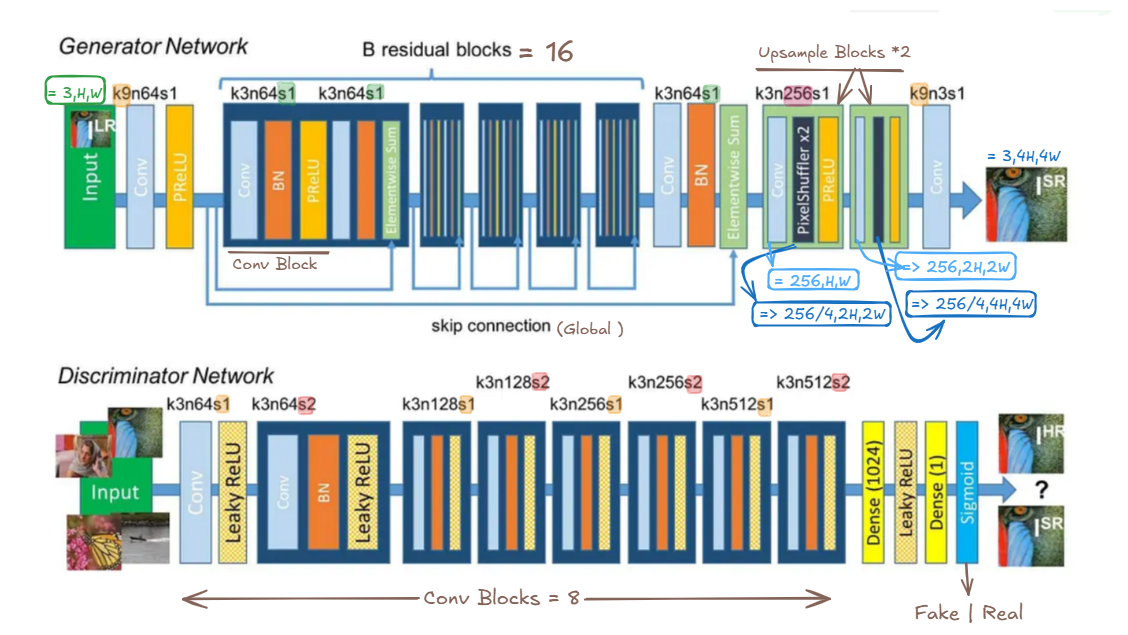

In [ ]:
display(IPImage("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/images/SRGAN_ARCH.png", width=1400))

In [ ]:
# =================================================================================================
#               Conv Block (Conv > BN > PRelu /LeakyRelu >)
#==================================================================================================
class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        discriminator=False,
        use_act=True,
        use_bn=True,
        **kwargs,):


        super().__init__()
        self.use_act = use_act
        self.cnn = nn.Conv2d(in_channels, out_channels, **kwargs, bias=not use_bn)
        self.bn = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.act = (
            nn.LeakyReLU(0.2, inplace=True)
            if discriminator
            else nn.PReLU(num_parameters=out_channels) )

    def forward(self, x):
        return self.act(self.bn(self.cnn(x))) if self.use_act else self.bn(self.cnn(x))


# =================================================================================================
#               UpSample Block (Conv,PixelShuffer,Prelu)(scale factor *2)
#==================================================================================================
class UpsampleBlock(nn.Module):
    def __init__(self, in_c, scale_factor):

        super().__init__()
        self.conv=nn.Conv2d(in_channels=in_c,out_channels=in_c * scale_factor ** 2,kernel_size=3,stride=1,padding=1)
        self.ps = nn.PixelShuffle(scale_factor)
        self.act = nn.PReLU(num_parameters=in_c)

    def forward(self, x):
        return self.act(self.ps(self.conv(x)))

# =================================================================================================
#               ResidualBlock (Conv,BN,PRelu,skipconnections with elementwise sum)()
#==================================================================================================

class ResidualBlock(nn.Module):
    def __init__(self, in_channels):

        super().__init__()
        self.block1 = ConvBlock(
            in_channels,
            in_channels,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.block2 = ConvBlock(
            in_channels,
            in_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            use_act=False,
        )

    def forward(self, x):
        out = self.block1(x)
        out = self.block2(out)
        return out + x

# =================================================================================================
#               Generator
#==================================================================================================
class Generator(nn.Module):
    def __init__(self, in_channels=3, num_channels=64, num_blocks=16):

        super().__init__()
        self.initial = ConvBlock(in_channels, num_channels, kernel_size=9, stride=1, padding=4, use_bn=False)
        self.residuals = nn.Sequential(*[ResidualBlock(num_channels) for _ in range(num_blocks)])
        self.convblock = ConvBlock(num_channels, num_channels, kernel_size=3, stride=1, padding=1, use_act=False)
        self.upsamples = nn.Sequential(UpsampleBlock(num_channels, 2), UpsampleBlock(num_channels, 2))
        self.final = nn.Conv2d(num_channels, in_channels, kernel_size=9, stride=1, padding=4)

    def forward(self, x):
        initial = self.initial(x)
        x = self.residuals(initial)
        x = self.convblock(x) + initial
        x = self.upsamples(x)
        return torch.tanh(self.final(x))

# =================================================================================================
#               Discriminator
#==================================================================================================
class Discriminator(nn.Module):
    def __init__(self, in_channels=3, features=[64, 64, 128, 128, 256, 256, 512, 512]):
        super().__init__()
        blocks = []
        for idx, feature in enumerate(features):
            blocks.append(
                ConvBlock(
                    in_channels,
                    feature,
                    kernel_size=3,
                    stride=1 + idx % 2,
                    padding=1,
                    discriminator=True, #
                    use_act=True,
                    use_bn=False if idx == 0 else True,)
            )
            in_channels = feature


        self.blocks = nn.Sequential(*blocks)

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((6, 6)),
            nn.Flatten(),
            nn.Linear(512*6*6, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1),
        )

    def forward(self, x):
        x = self.blocks(x)
        return self.classifier(x)

In [ ]:
gen = Generator().to(DEVICE)
disc = Discriminator().to(DEVICE)

low_resolution = 24
x = torch.randn((5, 3, low_resolution, low_resolution)).to(DEVICE)

with torch.no_grad():
    gen_out = gen(x)
    disc_out = disc(gen_out)

print("Generator output:", gen_out.shape)
print("Discriminator output:", disc_out.shape)

Generator output: torch.Size([5, 3, 96, 96])
Discriminator output: torch.Size([5, 1])


## 2.5-Perceptual Loss

**1. Generator Total Loss:**
$$l^{SR} = \underbrace{ \underbrace{l_{MSE}^{SR}}_{\text{Pixel Loss}} + \underbrace{l_{VGG}^{SR}}_{\text{VGG Loss}} }_{\text{Content Loss } (l_{X}^{SR})} + 10^{-3} \underbrace{l_{Gen}^{SR}}_{\text{Adversarial Loss}}$$


**A) MSE / Pixel Loss:**
$$l_{MSE}^{SR} = \frac{1}{r^2 W H} \sum_{x=1}^{rW} \sum_{y=1}^{rH} \left( I_{x,y}^{HR} - G_{\theta_G}(I^{LR})_{x,y} \right)^2$$

**B) VGG / Feature Loss:**
$$l_{VGG/i,j}^{SR} = \frac{1}{W_{i,j} H_{i,j}} \sum_{x=1}^{W_{i,j}} \sum_{y=1}^{H_{i,j}} \left( \phi_{i,j}(I^{HR})_{x,y} - \phi_{i,j}(G_{\theta_G}(I^{LR}))_{x,y} \right)^2$$

**C) Adversarial Loss:**
$$l_{Gen}^{SR} = \sum_{n=1}^{N} -\log(D_{\theta_D}(G_{\theta_G}(I^{LR})))$$

---
**2. Discriminator Loss:**

$$L_D = -\frac{1}{N} \sum_{n=1}^{N} \Big[ \underbrace{\log(D_{\theta_D}(I^{HR}))}_{\text{Real Loss(1)}} + \underbrace{\log(1 - D_{\theta_D}(G_{\theta_G}(I^{LR})))}_{\text{Fake Loss(0)}} \Big]$$

---
**Mathematical Notation:**
* $I^{HR}$ : High-Resolution Image.
* $I^{LR}$ : Low-Resolution Image.
* $G_{\theta_G}(I^{LR})$ : Fake Image.
* $D_{\theta_D}$ : Discriminator Network.
* $r$ : Upscaling Factor،
* $W, H$ : Width & Height.
* $\phi_{i,j}$ : Feature Map (VGG19).


In [ ]:
# Phi_5,4  5th conv layer before maxpooling but after activation
from torchvision.models import vgg19

class VGGLoss(nn.Module):
    def __init__(self):

        super().__init__()
        self.vgg = vgg19(pretrained=True).features[:36].eval().to(DEVICE)
        self.loss = nn.MSELoss()

        for param in self.vgg.parameters():
            param.requires_grad = False

    def forward(self, input, target):
        vgg_input_features = self.vgg(input)
        vgg_target_features = self.vgg(target)

        return self.loss(vgg_input_features, vgg_target_features)

## 2.6-Generator Warm Up

In [ ]:
# =========================================================================================================================
# Train Func : Batch of Data, Forward Pass[Gen[fake] = SR] ,Loss Func, Backpropagation, Optimization W , AVg Loss per epoch
# =========================================================================================================================

def train_fn(loader, gen, opt_gen, mse):
    loop = tqdm(loader, leave=True)

    gen.train()

    running_loss = 0.0

    for idx, (low_res, high_res) in enumerate(loop):

        high_res = high_res.to(DEVICE,non_blocking=True)

        low_res = low_res.to(DEVICE,non_blocking=True)

        # ==========================================
        # Train Generator using MSE only
        # ==========================================

        fake = gen(low_res)

        l2_loss = mse(fake,high_res)

        gen_loss = l2_loss

        opt_gen.zero_grad(set_to_none=True)

        gen_loss.backward()

        opt_gen.step()

        running_loss += gen_loss.item()

        loop.set_postfix(mse_loss=gen_loss.item())

        # ==========================================
        # Save visual examples
        # ==========================================

        if idx % 200 == 0:
            if (os.path.exists("test_images")and len(os.listdir("test_images")) > 0):

                plot_examples(
                    "test_images/",
                    gen,
                    device=DEVICE,
                    transform=test_transform)

    average_loss = running_loss / len(loader)
    return average_loss



# =========================================================================================================================
# Main : Prepare (Dataset , Dataloader) , Initialize (Generator,Optimaizer,Loss Func) , Load Model Checkpoint(if existed)
# Loop : Call Train func , Print(Avg Loss Per Epoch) , Save (Model , Optimizer) , Display (Valid Image)
# =========================================================================================================================
def main():

    train_path = ("/content/DIV2K_train_HR/DIV2K_train_HR")

    local_checkpoint_gen = CHECKPOINT_GEN

    # =====================================================
    # Dataset and DataLoader
    # =====================================================

    dataset = MyImageFolder(root_dir=train_path)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=torch.cuda.is_available(),
        num_workers=NUM_WORKERS,
    )

    # =====================================================
    # Generator
    # =====================================================

    gen = Generator(in_channels=3).to(DEVICE)

    # =====================================================
    # Generator Optimizer
    # =====================================================

    opt_gen = optim.Adam(
        gen.parameters(),
        lr=LEARNING_RATE,
        betas=(0.9, 0.999)
    )

    # =====================================================
    # Warm-up Loss: MSE only
    # =====================================================

    mse = nn.MSELoss()

    # =====================================================
    # Load Generator checkpoint
    # =====================================================

    if LOAD_MODEL:

        if os.path.exists(local_checkpoint_gen):

            load_checkpoint(
                local_checkpoint_gen,
                gen,
                opt_gen,
                LEARNING_RATE,
                device=DEVICE
            )

        else:
            print(
                "Generator checkpoint not found. "
                "Training from scratch."
            )

    # =====================================================
    # Generator Warm-up Loop
    # =====================================================

    print(
        f"Starting Generator warm-up "
        f"for {NUM_EPOCHS} epochs...")

    for epoch in range(NUM_EPOCHS):

        print(
            f"\n--- Warm-up Epoch "
            f"[{epoch + 1}/{NUM_EPOCHS}] ---")

        average_loss = train_fn(
            loader,
            gen,
            opt_gen,
            mse
        )

        print(
            f"Average MSE Loss: "
            f"{average_loss:.6f}")


        if SAVE_MODEL:

            save_checkpoint(
                gen,
                opt_gen,
                filename=local_checkpoint_gen
            )


if __name__ == "__main__":
    main()

Generator checkpoint not found. Training from scratch.
Starting Generator warm-up for 100 epochs...

--- Warm-up Epoch [1/100] ---


100%|██████████| 50/50 [00:39<00:00,  1.26it/s, mse_loss=0.0479]


Average MSE Loss: 0.111830
=> Saving checkpoint

--- Warm-up Epoch [2/100] ---


100%|██████████| 50/50 [00:39<00:00,  1.26it/s, mse_loss=0.0423]


Average MSE Loss: 0.057939
=> Saving checkpoint

--- Warm-up Epoch [3/100] ---


100%|██████████| 50/50 [00:39<00:00,  1.25it/s, mse_loss=0.0753]


... (191 outputs left out)

100%|██████████| 50/50 [00:40<00:00,  1.24it/s, mse_loss=0.0232]


Average MSE Loss: 0.015819
=> Saving checkpoint

--- Warm-up Epoch [100/100] ---


100%|██████████| 50/50 [00:40<00:00,  1.24it/s, mse_loss=0.00853]

Average MSE Loss: 0.014295
=> Saving checkpoint


In [ ]:
# =====================================================
# 1. Create Generator and load trained warm-up weights
# =====================================================
CHECKPOINT_GEN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen.pth.tar"
mse_gen_test = Generator(in_channels=3).to(DEVICE)

if os.path.exists(CHECKPOINT_GEN):
    load_model_weights_srgan(CHECKPOINT_GEN, mse_gen_test, DEVICE)
    LOADED_STAGE = "esrgan"
    mse_gen_test.eval()
    print("SRGAN Warmup ready for inference.")
else:
    print(f"Checkpoint not found: {CHECKPOINT_GEN}")

=> Loading SRGAN model for inference...
=> SRGAN model loaded successfully.
SRGAN Warmup ready for inference.


In [ ]:
# =====================================================
# 2. Test all LR images
# =====================================================

test_folder = "test_images"
output_folder = "srgan_mse_val"

os.makedirs(output_folder, exist_ok=True)

files = sorted(os.listdir(test_folder))

print(f"Found {len(files)} file(s) inside {test_folder}")

saved_count = 0

with torch.no_grad():

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(test_folder, file)

        image = Image.open(image_path).convert("RGB")
        image = np.asarray(image)

        image = (
            test_transform(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE))


        sr = mse_gen_test(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)

        output_path = os.path.join(
            output_folder,
            f"MSE_{name}_SR{ext}"
        )

        save_image(
            (sr * 0.5 + 0.5).clamp(0, 1),
            output_path)

        print(f"Saved: {output_path} ")

        saved_count += 1


print(f"\nFinished testing. Saved {saved_count} image(s).")
print(f"Output folder: {os.path.abspath(output_folder)}")

Found 1 file(s) inside test_images
Saved: srgan_mse_val/MSE_baboon_SR.png 

Finished testing. Saved 1 image(s).
Output folder: /content/srgan_mse_val


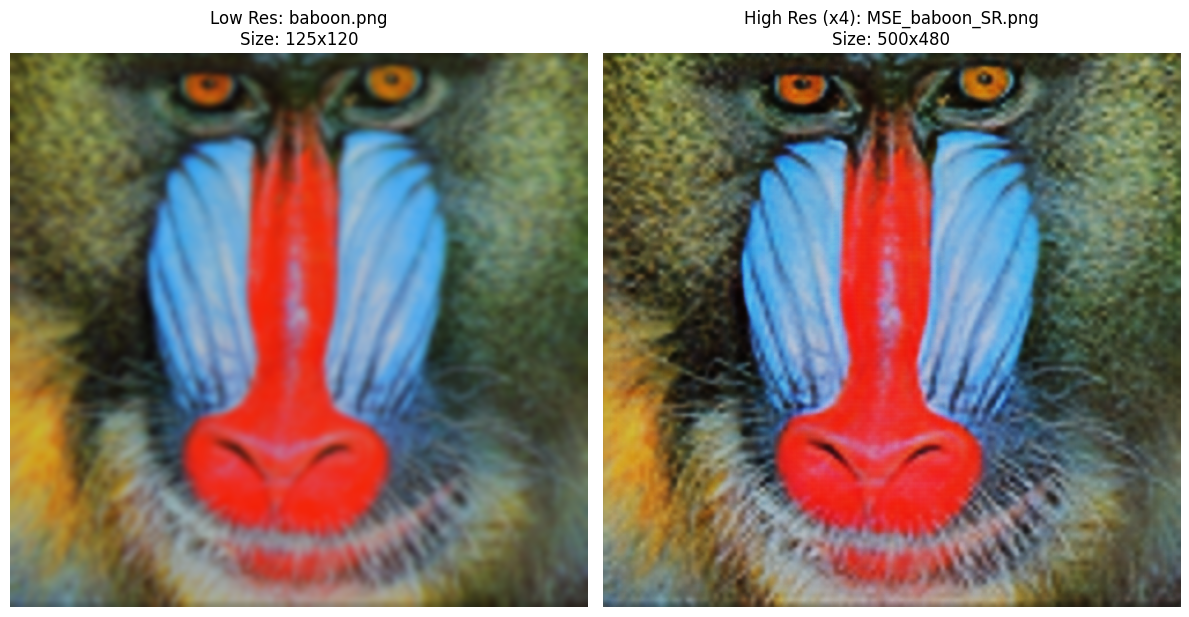

In [ ]:
path1 = "/content/test_images/baboon.png"
path2 = "/content/srgan_mse_val/MSE_baboon_SR.png"

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))


axes[0].imshow(img1,interpolation='bicubic')
axes[0].set_title(f"Low Res: {os.path.basename(path1)}\nSize: {img1.shape[1]}x{img1.shape[0]}", fontsize=12)
axes[0].axis('off')


axes[1].imshow(img2)
axes[1].set_title(f"High Res (x4): {os.path.basename(path2)}\nSize: {img2.shape[1]}x{img2.shape[0]}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 2.7-GAN Training

In [ ]:
#Load warmup
import torch
from torch import optim


CHECKPOINT_WARMUP_GEN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen.pth.tar"

gen = Generator(in_channels=3).to(DEVICE)
disc = Discriminator(in_channels=3).to(DEVICE)

opt_gen = optim.Adam(
    gen.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)

opt_disc = optim.Adam(
    disc.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)


load_checkpoint(
    CHECKPOINT_WARMUP_GEN,
    gen,
    opt_gen,
    LEARNING_RATE,
    device=DEVICE
)
LOADED_STAGE = "warmup"

print("Warm-up Generator loaded.")
print("Discriminator starts from scratch.")

=> Loading checkpoint
Warm-up Generator loaded.
Discriminator starts from scratch.


In [ ]:
# load Gan
import torch
from torch import optim

CHECKPOINT_GAN_GEN = ("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen_gan.pth.tar")

CHECKPOINT_GAN_DISC = ("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/disc_gan.pth.tar")

gen = Generator(in_channels=3).to(DEVICE)
disc = Discriminator(in_channels=3).to(DEVICE)

opt_gen = optim.Adam(
    gen.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)

opt_disc = optim.Adam(
    disc.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)

load_checkpoint(
    CHECKPOINT_GAN_GEN,
    gen,
    opt_gen,
    LEARNING_RATE,
    device=DEVICE
)

load_checkpoint(
    CHECKPOINT_GAN_DISC,
    disc,
    opt_disc,
    LEARNING_RATE,
    device=DEVICE
)
LOADED_STAGE = "gan"

print("GAN Generator loaded.")
print("GAN Discriminator loaded.")
print("Ready to continue GAN training.")

=> Loading checkpoint
=> Loading checkpoint
GAN Generator loaded.
GAN Discriminator loaded.
Ready to continue GAN training.


In [ ]:
# ==================================================================================================================
# Train Function
# ==================================================================================================================
def train_fn(
    loader,
    disc,
    gen,
    opt_gen,
    opt_disc,
    mse,
    bce,
    vgg_loss
):
    loop = tqdm(loader, leave=True)

    gen.train()
    disc.train()

    total_disc_loss = 0.0
    total_gen_loss = 0.0
    total_pixel_loss = 0.0
    total_vgg_loss = 0.0
    total_weighted_vgg = 0.0
    total_adv_loss = 0.0

    for low_res, high_res in loop:

        low_res = low_res.to(DEVICE,non_blocking=True)

        high_res = high_res.to(DEVICE, non_blocking=True)

        # =================================================
        # 1. Train Discriminator
        # =================================================

        fake = gen(low_res)

        # Prediction of Disc
        disc_real = disc(high_res)
        disc_fake = disc(fake.detach())

        # Real Labels
        real_labels = (torch.ones_like(disc_real)- 0.1 * torch.rand_like(disc_real))
        fake_labels = torch.zeros_like(disc_fake)

        #Compute Losses
        disc_loss_real = bce(disc_real,real_labels)
        disc_loss_fake = bce(disc_fake,fake_labels)

        loss_disc = (disc_loss_real+ disc_loss_fake)

        opt_disc.zero_grad(set_to_none=True)
        loss_disc.backward()
        opt_disc.step()

        # =================================================
        # 2. Train Generator
        # =================================================

        # Predection of Disc
        disc_fake = disc(fake)

        # MSE Loss
        pixel_loss = 0.05*mse(fake,high_res)

        #vgg Loss (constant = 0.006)
        perceptual_loss = vgg_loss(fake,high_res)
        loss_for_vgg = (0.04* perceptual_loss)

        #ADV Loss (constant = 1e-3)
        adversarial_loss = (1e-5* bce(disc_fake,torch.ones_like(disc_fake)))

        gen_loss = (pixel_loss+ loss_for_vgg+ adversarial_loss)

        opt_gen.zero_grad(set_to_none=True)
        gen_loss.backward()
        opt_gen.step()

        # =================================================
        # Collect losses
        # =================================================

        total_disc_loss += loss_disc.item()
        total_gen_loss += gen_loss.item()
        total_pixel_loss += pixel_loss.item()
        total_vgg_loss += perceptual_loss.item()
        total_weighted_vgg += loss_for_vgg.item()
        total_adv_loss += adversarial_loss.item()

        loop.set_postfix(
            disc_loss=loss_disc.item(),
            gen_loss=gen_loss.item(),
            pixel_loss=pixel_loss.item(),
            vgg_loss=perceptual_loss.item(),
            weighted_vgg=loss_for_vgg.item(),
            adv_loss=adversarial_loss.item(),
        )

    # =====================================================
    # Epoch averages
    # =====================================================

    num_batches = len(loader)

    return (
        total_disc_loss / num_batches,
        total_gen_loss / num_batches,
        total_pixel_loss / num_batches,
        total_vgg_loss / num_batches,
        total_weighted_vgg / num_batches,
        total_adv_loss / num_batches,
    )


# ==================================================================================================================
# Main training
# ==================================================================================================================

def main():


    required_objects = ["gen","disc","opt_gen","opt_disc",]

    missing_objects = [name for name in required_objects if name not in globals()]

    if missing_objects:
        raise RuntimeError(
            "Run one loading cell first. Missing objects: "
            + ", ".join(missing_objects)
        )
    print(" Generator object found.")
    print(" Discriminator object found.")
    print(" Generator optimizer found.")
    print(" Discriminator optimizer found.")

    if "LOADED_STAGE" not in globals():
        raise RuntimeError("Run one loading cell first.")

    print(f"\n========== {LOADED_STAGE.upper()} ==========\n")

    train_path = ("/content/DIV2K_train_HR/DIV2K_train_HR")

    CHECKPOINT_GAN_GEN = ("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen_gan.pth.tar")

    CHECKPOINT_GAN_DISC = ("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/disc_gan.pth.tar")

    # =====================================================
    # Dataset and DataLoader
    # =====================================================

    dataset = MyImageFolder( root_dir=train_path)

    loader = DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=True,pin_memory=torch.cuda.is_available(),num_workers=NUM_WORKERS,)

    # =====================================================
    # Loss functions
    # =====================================================

    mse = nn.MSELoss()
    bce = nn.BCEWithLogitsLoss()
    vgg_loss = VGGLoss().to(DEVICE)

    # =====================================================
    # Training loop
    # =====================================================

    print(
        f"Starting GAN training for "
        f"{NUM_EPOCHS} epochs...")

    for epoch in range(NUM_EPOCHS):

        print(
            f"\n--- GAN Epoch "
            f"[{epoch + 1}/{NUM_EPOCHS}] ---" )

        (
            avg_disc_loss,
            avg_gen_loss,
            avg_pixel_loss,
            avg_vgg_loss,
            avg_weighted_vgg,
            avg_adv_loss,
        ) = train_fn(
            loader,
            disc,
            gen,
            opt_gen,
            opt_disc,
            mse,
            bce,
            vgg_loss
        )

        print(
            f"Average Losses | "
            f"Disc: {avg_disc_loss:.6f} | "
            f"Gen: {avg_gen_loss:.6f} | "
            f"Pixel: {avg_pixel_loss:.6f} | "
            f"VGG: {avg_vgg_loss:.6f} | "
            f"Weighted VGG: {avg_weighted_vgg:.6f} | "
            f"Adv: {avg_adv_loss:.6f}"
        )

        # =================================================
        # Test images after every epoch
        # =================================================

        if (os.path.isdir("test_images") and any( file.lower().endswith((".png", ".jpg", ".jpeg"))
                for file in os.listdir("test_images") ) ):
            plot_examples(
                "test_images/",
                gen,
                device=DEVICE,
                transform=test_transform
            )

        # =================================================
        # Save GAN checkpoints
        # =================================================

        if SAVE_MODEL:

            save_checkpoint(gen,opt_gen,filename=CHECKPOINT_GAN_GEN)

            save_checkpoint(disc,opt_disc,filename=CHECKPOINT_GAN_DISC)


main()

 Generator object found.
 Discriminator object found.
 Generator optimizer found.
 Discriminator optimizer found.

========== GAN ==========

Starting GAN training for 20 epochs...

--- GAN Epoch [1/20] ---


100%|██████████| 50/50 [00:40<00:00,  1.25it/s, adv_loss=0.000104, disc_loss=0.185, gen_loss=0.00575, pixel_loss=0.000512, vgg_loss=0.128, weighted_vgg=0.00514]


Average Losses | Disc: 0.199460 | Gen: 0.006816 | Pixel: 0.000738 | VGG: 0.149445 | Weighted VGG: 0.005978 | Adv: 0.000101
=> Saving checkpoint
=> Saving checkpoint

--- GAN Epoch [2/20] ---


100%|██████████| 50/50 [00:39<00:00,  1.26it/s, adv_loss=9.81e-5, disc_loss=0.225, gen_loss=0.011, pixel_loss=0.00106, vgg_loss=0.245, weighted_vgg=0.00981]


Average Losses | Disc: 0.204145 | Gen: 0.006822 | Pixel: 0.000772 | VGG: 0.148548 | Weighted VGG: 0.005942 | Adv: 0.000108
=> Saving checkpoint
=> Saving checkpoint

--- GAN Epoch [3/20] ---


100%|██████████| 50/50 [00:40<00:00,  1.25it/s, adv_loss=0.0001, disc_loss=0.191, gen_loss=0.00654, pixel_loss=0.000716, vgg_loss=0.143, weighted_vgg=0.00573]


... (31 outputs left out)

100%|██████████| 50/50 [00:40<00:00,  1.24it/s, adv_loss=0.000138, disc_loss=0.223, gen_loss=0.00717, pixel_loss=0.000927, vgg_loss=0.153, weighted_vgg=0.00611]


Average Losses | Disc: 0.199740 | Gen: 0.006766 | Pixel: 0.000782 | VGG: 0.146050 | Weighted VGG: 0.005842 | Adv: 0.000141
=> Saving checkpoint
=> Saving checkpoint

--- GAN Epoch [20/20] ---


100%|██████████| 50/50 [00:39<00:00,  1.26it/s, adv_loss=0.00014, disc_loss=0.196, gen_loss=0.00352, pixel_loss=0.000544, vgg_loss=0.0709, weighted_vgg=0.00284]


Average Losses | Disc: 0.196326 | Gen: 0.006838 | Pixel: 0.000800 | VGG: 0.147396 | Weighted VGG: 0.005896 | Adv: 0.000142
=> Saving checkpoint
=> Saving checkpoint


In [ ]:
srgan_gen_test = Generator(in_channels=3).to(DEVICE)

CHECKPOINT_GAN_GEN = ("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/gen_gan.pth.tar")

load_model_weights_srgan(CHECKPOINT_GAN_GEN,srgan_gen_test,DEVICE)

srgan_gen_test.eval()

print("GAN Generator ready for inference.")

=> Loading SRGAN model for inference...
=> SRGAN model loaded successfully.
GAN Generator ready for inference.


In [ ]:
test_folder = "test_images"
output_folder = "srgan_val"

os.makedirs(output_folder, exist_ok=True)

srgan_gen_test.eval()

with torch.no_grad():

    files = sorted(os.listdir(test_folder))

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)

        image = (
            test_transform(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE))

        sr = srgan_gen_test(image)

        name, ext = os.path.splitext(file)

        name = name.replace("lr_", "", 1)

        save_image((sr * 0.5 + 0.5).clamp(0, 1),os.path.join(output_folder,f"SRGAN_{name}_SR{ext}"))

srgan_gen_test.train()

print(f"Finished! Results saved in '{output_folder}'")

Finished! Results saved in 'srgan_val'


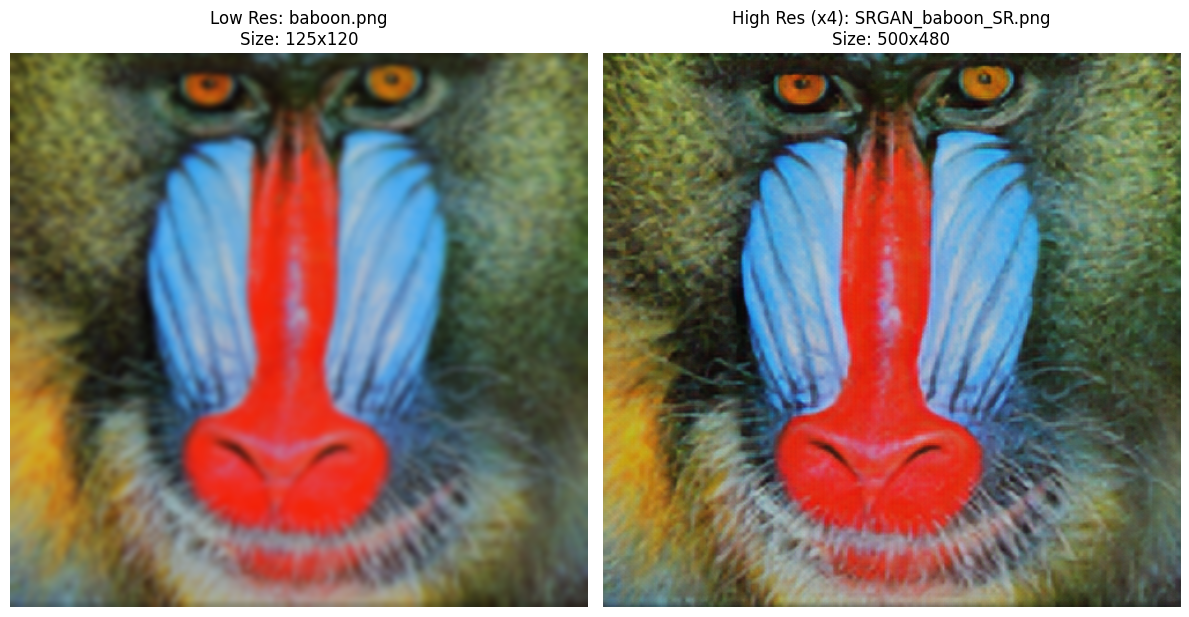

In [ ]:
path1 = "/content/test_images/baboon.png"
path2 = "/content/srgan_val/SRGAN_baboon_SR.png"

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))


axes[0].imshow(img1,interpolation='bicubic')
axes[0].set_title(f"Low Res: {os.path.basename(path1)}\nSize: {img1.shape[1]}x{img1.shape[0]}", fontsize=12)
axes[0].axis('off')


axes[1].imshow(img2)
axes[1].set_title(f"High Res (x4): {os.path.basename(path2)}\nSize: {img2.shape[1]}x{img2.shape[0]}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# (3)-MODEL 2: ESRGAN

## 3.1-Config

In [ ]:
CHECKPOINT_GEN_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_gen.pth.tar"
CHECKPOINT_DISC_ESRAGN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_disc.pth.tar"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LOAD_MODEL = True
SAVE_MODEL = True


LEARNING_RATE = 1e-4
NUM_EPOCHS = 100
BATCH_SIZE = 16
LAMBDA_GP = 10
NUM_WORKERS = 2
HIGH_RES = 128
LOW_RES = HIGH_RES // 4
IMG_CHANNELS = 3

In [ ]:
both_transforms_esrgan = A.Compose(
    [
        A.RandomCrop(width=HIGH_RES, height=HIGH_RES),
        A.HorizontalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
    ]
)

# Normalization [0:1] Not [-1:1] Like SRGAN
highres_transform_esrgan = A.Compose(
    [
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1]),
        ToTensorV2(),
    ]
)

lowres_transform_esrgan = A.Compose(
    [
        A.Resize(width=LOW_RES, height=LOW_RES, interpolation=Image.BICUBIC),
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1]),
        ToTensorV2(),
    ]
)



test_transform_esrgan = A.Compose(
    [
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1]),
        ToTensorV2(),
    ]
)

print(f"Using device: {DEVICE}")

Using device: cuda


## 3.2-Utils

In [ ]:
def save_checkpoint_esrgan(model, optimizer, filename="my_checkpoint.pth.tar"):
    print("=> Saving checkpoint")
    checkpoint = {
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
    }
    torch.save(checkpoint, filename)

In [ ]:
def load_checkpoint_esrgan(checkpoint_file, model, optimizer, lr,device):
    print("=> Loading checkpoint")
    checkpoint = torch.load(checkpoint_file, map_location=DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

In [ ]:
def plot_examples_esrgan(gen_esrgan, low_res_folder="test_images"):

    os.makedirs("test_images", exist_ok=True)
    os.makedirs("saved", exist_ok=True)

    files = os.listdir(low_res_folder)


    valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')
    image_files = [f for f in files if f.lower().endswith(valid_extensions)]

    if len(image_files) == 0:
        print("folder is empty")
        return

    gen_esrgan.eval()
    for file in image_files:
        image_path = os.path.join(low_res_folder, file)
        try:
            image = Image.open(image_path).convert("RGB")
            with torch.no_grad():
                upscaled_img = gen_esrgan(
                    test_transform_esrgan(image=np.asarray(image))["image"]
                    .unsqueeze(0)
                    .to(DEVICE)
                )
            save_image(upscaled_img, f"saved/{file}")
            print(f" saved/{file}")
        except Exception as e:
            print(f"error {file}: {e}")
            continue

    gen_esrgan.train()

In [ ]:
def initialize_weights(model, scale=0.1):
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight.data)
            m.weight.data *= scale

        elif isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight.data)
            m.weight.data *= scale

In [ ]:
def load_model_weights_esrgan(checkpoint_file, model, device):
    print("=> Loading ESRGAN model for inference...")
    checkpoint = torch.load(checkpoint_file, map_location=device)
    model.load_state_dict(checkpoint["state_dict"])
    print("=> ESRGAN model loaded successfully.")

## 3.3-Dataset

In [ ]:
import cv2
class MyImageFolder_esrgan(Dataset):
    def __init__(self, root_dir):
        super(MyImageFolder_esrgan, self).__init__()
        self.root_dir = root_dir

        self.images = [f for f in os.listdir(root_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        img_file = self.images[index]
        img_path = os.path.join(self.root_dir, img_file)


        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


        both_transform = both_transforms_esrgan(image=image)["image"]
        low_res = lowres_transform_esrgan(image=both_transform)["image"]
        high_res = highres_transform_esrgan(image=both_transform)["image"]

        return low_res, high_res

In [ ]:
train_dataset_esrgan = MyImageFolder_esrgan(train_path)
valid_dataset_esrgan = MyImageFolder_esrgan(valid_path)

print("ESRGAN Train size:", len(train_dataset_esrgan))
print("ESRGAN Valid size:", len(valid_dataset_esrgan))
print("="*50)

train_loader_esrgan = DataLoader(
    train_dataset_esrgan,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

valid_loader_esrgan = DataLoader(
    valid_dataset_esrgan,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

try:
    low_res, high_res = next(iter(train_loader_esrgan))
    print("ESRGAN Training DataLoader ")
    print("Low Res Shape :", low_res.shape)
    print("High Res Shape ", high_res.shape)
except Exception as e:
    print(f"Error {e}")

print("="*50)


try:
    low_res, high_res = next(iter(valid_loader_esrgan))
    print("ESRGAN Valid DataLoader ")
    print("Low Res Shape :", low_res.shape)
    print("High Res Shape ", high_res.shape)
except Exception as e:
    print(f"Error {e}")

ESRGAN Train size: 800
ESRGAN Valid size: 100
ESRGAN Training DataLoader 
Low Res Shape : torch.Size([16, 3, 32, 32])
High Res Shape  torch.Size([16, 3, 128, 128])
ESRGAN Valid DataLoader 
Low Res Shape : torch.Size([1, 3, 32, 32])
High Res Shape  torch.Size([1, 3, 128, 128])


## 3.4-Model

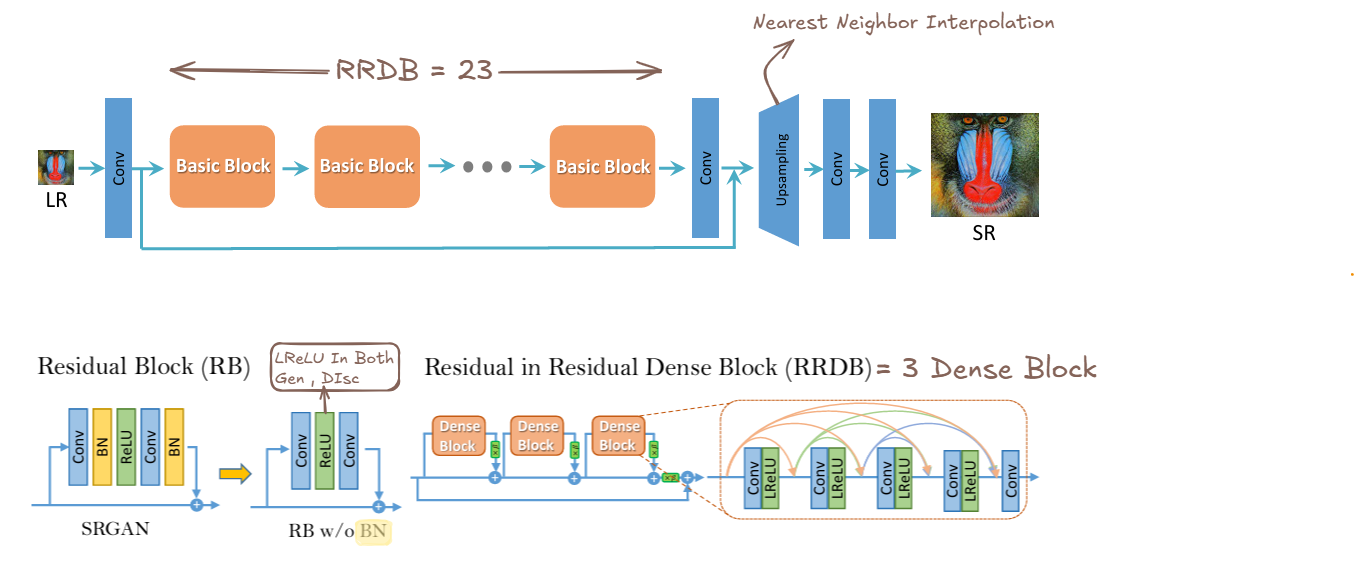

In [ ]:
display(IPImage("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/images/ESRGAN_ARCH.png", width=1400))

In [ ]:
# =================================================================================================
#               ConvBlock (Conv + LRelu) (No BN)
#==================================================================================================
class ConvBlock_esrgan(nn.Module):
    def __init__(self, in_channels, out_channels, use_act, **kwargs):
        super().__init__()

        self.cnn = nn.Conv2d(
            in_channels,
            out_channels,
            **kwargs,
            bias=True, )

        self.act = nn.LeakyReLU(0.2, inplace=True) if use_act else nn.Identity()

    def forward(self, x):
        return self.act(self.cnn(x))

# =================================================================================================
#               UpSample Block (Conv,nearest upsample,Prelu)(scale factor *2)
#==================================================================================================
class UpsampleBlock_esrgan(nn.Module):
    def __init__(self, in_c, scale_factor=2):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=scale_factor, mode="nearest")
        self.conv = nn.Conv2d(in_c, in_c, 3, 1, 1, bias=True)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        return self.act(self.conv(self.upsample(x)))

# =================================================================================================
#               DenseResidualBlock (4 Conv , 3 LRelu)
#==================================================================================================
class DenseResidualBlock(nn.Module):
    def __init__(self, in_channels, channels=32, residual_beta=0.2):

        super().__init__()
        self.residual_beta = residual_beta
        self.blocks = nn.ModuleList()

        for i in range(5):
            self.blocks.append(
                ConvBlock_esrgan(
                    in_channels + channels * i,
                    channels if i <= 3 else in_channels,
                    kernel_size=3,
                    stride=1,
                    padding=1,
                    use_act=True if i <= 3 else False,)
            )


    def forward(self, x):
        new_inputs = x
        for block in self.blocks:
            out = block(new_inputs)
            new_inputs = torch.cat([new_inputs, out], dim=1)
        return self.residual_beta * out + x

"""
block (1)
  out = (x)
  out= 32 channels
  new input = 64 + 32 =96

block (2)
  out = (new input = 96)
  out= 32 channels
  new input = 96 + 32 =128

block (5)
  out = (new input = 192)
  out= 64 channels

return 0.2*64 + x(x=64) >> eleentwise add

"""

# =================================================================================================
#               RRDB (3 Dense Blocks)
#==================================================================================================
class RRDB(nn.Module):
    def __init__(self, in_channels, residual_beta=0.2):
        super().__init__()
        self.residual_beta = residual_beta
        self.rrdb = nn.Sequential(*[DenseResidualBlock(in_channels) for _ in range(3)])

    def forward(self, x):
        return self.rrdb(x) * self.residual_beta + x

# =================================================================================================
#               Generator
#==================================================================================================
class Generator_esrgan(nn.Module):

    def __init__(self, in_channels=3, num_channels=64, num_blocks=23):
        super().__init__()
        self.initial = nn.Conv2d(
            in_channels,
            num_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=True,
        )

        self.residuals = nn.Sequential(*[RRDB(num_channels) for _ in range(num_blocks)])
        self.conv = nn.Conv2d(num_channels, num_channels, kernel_size=3, stride=1, padding=1)
        self.upsamples = nn.Sequential(
            UpsampleBlock_esrgan(num_channels), UpsampleBlock_esrgan(num_channels),)

        self.final = nn.Sequential(
            nn.Conv2d(num_channels, num_channels, 3, 1, 1, bias=True),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(num_channels, in_channels, 3, 1, 1, bias=True),
        )

    def forward(self, x):
        initial = self.initial(x)
        x = self.conv(self.residuals(initial)) + initial
        x = self.upsamples(x)
        return self.final(x)

# =================================================================================================
#               Discriminator
#==================================================================================================
class Discriminator_esrgan(nn.Module):
  #conv(64),conv(64),conv(128),conv(128),conv(256),conv(256),conv(512),conv(512)
    def __init__(self, in_channels=3, features=[64, 64, 128, 128, 256, 256, 512, 512]):
        super().__init__()
        blocks = []
        for idx, feature in enumerate(features):
            blocks.append(
                ConvBlock_esrgan(
                    in_channels,
                    feature,
                    kernel_size=3,
                    stride=1 + idx % 2,
                    padding=1,
                    use_act=True,),
            )
            in_channels = feature

        self.blocks = nn.Sequential(*blocks)
        #pooling , flatten , fc1 , relu , fc2
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((6, 6)),
            nn.Flatten(),
            nn.Linear(512 * 6 * 6, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1),
        )

    def forward(self, x):
        x = self.blocks(x)
        return self.classifier(x)

In [ ]:
gen_esrgan = Generator_esrgan().to(DEVICE)
disc_esrgan = Discriminator_esrgan().to(DEVICE)

low_resolution = 32
x = torch.randn((5, 3, low_resolution, low_resolution)).to(DEVICE)

with torch.no_grad():
    gen_esrgan_out = gen_esrgan(x)
    disc_esrgan_out = disc_esrgan(gen_esrgan_out)

print("ESRGAN Generator output:", gen_esrgan_out.shape)
print("ESRGAN Discriminator output:", disc_esrgan_out.shape)

ESRGAN Generator output: torch.Size([5, 3, 128, 128])
ESRGAN Discriminator output: torch.Size([5, 1])


## 3.5-Perceptual Loss

**ESRGAN Loss Functions (Enhanced SRGAN)**  
The ESRGAN architecture improves upon SRGAN by making three fundamental changes to the loss functions:

---

**1. Pixel Loss ($L_1$ instead of $L_2$)**  
Instead of Mean Squared Error (MSE), ESRGAN uses Mean Absolute Error ($L_1$ Loss) to penalize the pixel-wise differences, which prevents blurry artifacts and helps the model converge better:
$$L_{pixel} = \mathbb{E}_{x_i} \left[ \left\| I^{HR} - G(I^{LR}) \right\|_1 \right]$$

---

**2. Perceptual Loss (Pre-activation VGG)**
The perceptual loss is computed using VGG features **before** the activation function (like ReLU) rather than after. This preserves more low-level feature information and provides sharper edges. Mathematically, it is calculated as the MSE between these pre-activation feature maps:

$$L_{percep} = \frac{1}{W_{i,j} H_{i,j}} \sum_{x=1}^{W_{i,j}} \sum_{y=1}^{H_{i,j}} \left( \phi_{i,j}(I^{HR})_{x,y} - \phi_{i,j}(G_{\theta_G}(I^{LR}))_{x,y} \right)^2$$

*(Note: $\phi_{i,j}$ here strictly represents the VGG feature map before the activation layer, unlike standard SRGAN).*

---

**3. Adversarial Loss (Relativistic Average GAN - RaGAN)**  
Instead of predicting absolute realism, the Relativistic Discriminator predicts the probability that one image is relatively more realistic than another.

First, the network calculates two **Relative Scores**:
1. The probability that the Real image is more realistic than the Fake:
$$D_{Ra}(x_r, x_f) = \sigma \left( C(x_r) - \mathbb{E}_{x_f}[C(x_f)] \right)$$
2. The probability that the Fake image is more realistic than the Real:
$$D_{Ra}(x_f, x_r) = \sigma \left( C(x_f) - \mathbb{E}_{x_r}[C(x_r)] \right)$$
*(Where $C(x)$ is the raw discriminator output before activation, and $\sigma$ is the sigmoid function).*  
*( $\mathbb{E}$ : The Expectation (represents the mathematical average/mean over a mini-batch) ).*


**Generator Adversarial Loss:**
The generator, on the other hand, tries to fool the discriminator into believing the fake images are more realistic than the real ones. Its loss function penalizes both terms symmetrically:
$$L_{G}^{Ra} = - \mathbb{E}_{x_r} \left[ \log(1 - D_{Ra}(x_r, x_f)) \right] - \mathbb{E}_{x_f} \left[ \log(D_{Ra}(x_f, x_r)) \right]$$


---
**Total ESRGAN Generator Loss:**
The final objective function for the ESRGAN Generator is a weighted sum of the Content (Pixel + VGG) and Adversarial losses:
$$L_{G}^{total} = L_{percep} + \lambda L_{G}^{Ra} + \eta L_{pixel}$$

---
**Discriminator Adversarial Loss:**
The discriminator is trained to maximize the score of real images and minimize the score of fake images. Its loss function is defined as:
$$L_{D}^{Ra} = - \mathbb{E}_{x_r} \left[ \log(D_{Ra}(x_r, x_f)) \right] - \mathbb{E}_{x_f} \left[ \log(1 - D_{Ra}(x_f, x_r)) \right]$$

In [ ]:
class VGGLoss_esrgan(nn.Module):
    def __init__(self):
        super().__init__()
        self.vgg = vgg19(pretrained=True).features[:35].eval().to(DEVICE)

        for param in self.vgg.parameters():
            param.requires_grad = False

        self.loss = nn.MSELoss()

    def forward(self, input, target):
        vgg_input = self.vgg(input)
        vgg_target = self.vgg(target)
        return self.loss(vgg_input, vgg_target)

## 3.6-Generator Warm Up

In [ ]:
# AMP = Auotomatic Mixed Percision , g = grad scaler , fp =16 not 32 bits
def train_fn_warmup_esrgan(loader, esrgan_gen, opt_gen_esrgan, l1, g_scaler):
    loop = tqdm(loader, leave=True)
    esrgan_gen.train()
    running_loss = 0.0
    device_type = 'cuda' if torch.cuda.is_available() else 'cpu'

    for idx, (low_res, high_res) in enumerate(loop):
        high_res = high_res.to(DEVICE, non_blocking=True)
        low_res = low_res.to(DEVICE, non_blocking=True)

        #######################################
        # Forward Pass
        #######################################
        with torch.amp.autocast(device_type):
            fake = esrgan_gen(low_res)
            l1_loss = l1(fake, high_res)

        #######################################
        # Backward Pass
        #######################################
        opt_gen_esrgan.zero_grad(set_to_none=True)

        if g_scaler is not None:
            g_scaler.scale(l1_loss).backward()
            g_scaler.step(opt_gen_esrgan)
            g_scaler.update()
        else:
            l1_loss.backward()
            opt_gen_esrgan.step()

        #######################################
        # Loss
        #######################################
        running_loss += l1_loss.item()
        loop.set_postfix(l1_loss=l1_loss.item())


    if os.path.exists("test_images") and len(os.listdir("test_images")) > 0:
        esrgan_gen.eval()
        plot_examples_esrgan(esrgan_gen)
        esrgan_gen.train()

    average_loss = running_loss / len(loader)
    return average_loss


def main():
    train_path = "/content/DIV2K_train_HR/DIV2K_train_HR"
    CHECKPOINT_GEN_esrgan_WARMUP = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/warmup_gen.pth.tar"

    # =====================================================
    # Dataset and DataLoader
    # =====================================================
    dataset = MyImageFolder_esrgan(root_dir=train_path)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=torch.cuda.is_available(),
        num_workers=NUM_WORKERS,
    )

    # =====================================================
    # Generator & Optimizer
    # =====================================================
    esrgan_gen = Generator_esrgan(in_channels=3).to(DEVICE)

    opt_gen_esrgan = optim.Adam(
        esrgan_gen.parameters(),
        lr=LEARNING_RATE,
        betas=(0.9, 0.999)
    )

    # =====================================================
    # Warm-up Loss (L1) & Scaler
    # =====================================================
    l1 = nn.L1Loss()
    g_scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

    # =====================================================
    # Load Generator checkpoint
    # =====================================================
    if LOAD_MODEL:
        if os.path.exists(CHECKPOINT_GEN_esrgan_WARMUP):
            load_checkpoint_esrgan(
                CHECKPOINT_GEN_esrgan_WARMUP,
                esrgan_gen,
                opt_gen_esrgan,
                LEARNING_RATE,
                device=DEVICE
            )
            print("Warm-up checkpoint loaded successfully.")
        else:
            print("Warm-up Generator checkpoint not found. Training from scratch.")

    # =====================================================
    # Generator Warm-up Loop
    # =====================================================
    print(f"Starting ESRGAN Generator warm-up for {NUM_EPOCHS} epochs...")

    for epoch in range(NUM_EPOCHS):
        print(f"\n--- Warm-up Epoch [{epoch + 1}/{NUM_EPOCHS}] ---")

        average_loss = train_fn_warmup_esrgan(
            loader=loader,
            esrgan_gen=esrgan_gen,
            opt_gen_esrgan=opt_gen_esrgan,
            l1=l1,
            g_scaler=g_scaler
        )

        print(f"Average L1 Loss: {average_loss:.6f}")


        if SAVE_MODEL:
            save_checkpoint_esrgan(
                model=esrgan_gen,
                optimizer=opt_gen_esrgan,
                filename=CHECKPOINT_GEN_esrgan_WARMUP
            )
            print(f"=> Saved checkpoint to {CHECKPOINT_GEN_esrgan_WARMUP}")

if __name__ == "__main__":
    main()

In [ ]:
CHECKPOINT_GEN_esrgan_WARMUP = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/warmup_gen.pth.tar"

l1_gen = Generator_esrgan(in_channels=3).to(DEVICE)

if os.path.exists(CHECKPOINT_GEN_esrgan_WARMUP):
    load_model_weights_esrgan(CHECKPOINT_GEN_esrgan_WARMUP, l1_gen, DEVICE)
    LOADED_STAGE = "warmup"
    l1_gen.eval()
    print("Warm-up Generator ready for inference.")
else:
    print(f"Checkpoint not found: {CHECKPOINT_GEN_esrgan_WARMUP}")

=> Loading ESRGAN model for inference...
=> ESRGAN model loaded successfully.
Warm-up Generator ready for inference.


In [ ]:
# ==========================================
# Validation on test_images (Warm-up L1)
# ==========================================

test_folder = "test_images"
output_folder = "esrgan_l1_val"

os.makedirs(output_folder, exist_ok=True)

l1_gen.eval()

with torch.no_grad():
    files = sorted(os.listdir(test_folder))

    for file in files:
        if not file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)

        image = (
            test_transform_esrgan(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE) )

        sr = l1_gen(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)


        save_image(
            sr.clamp(0, 1),
            os.path.join(output_folder,f"L1_{name}_SR{ext}")
            )

l1_gen.train()

print(f"Finished! Results saved in '{output_folder}'")

Finished! Results saved in 'esrgan_l1_val'


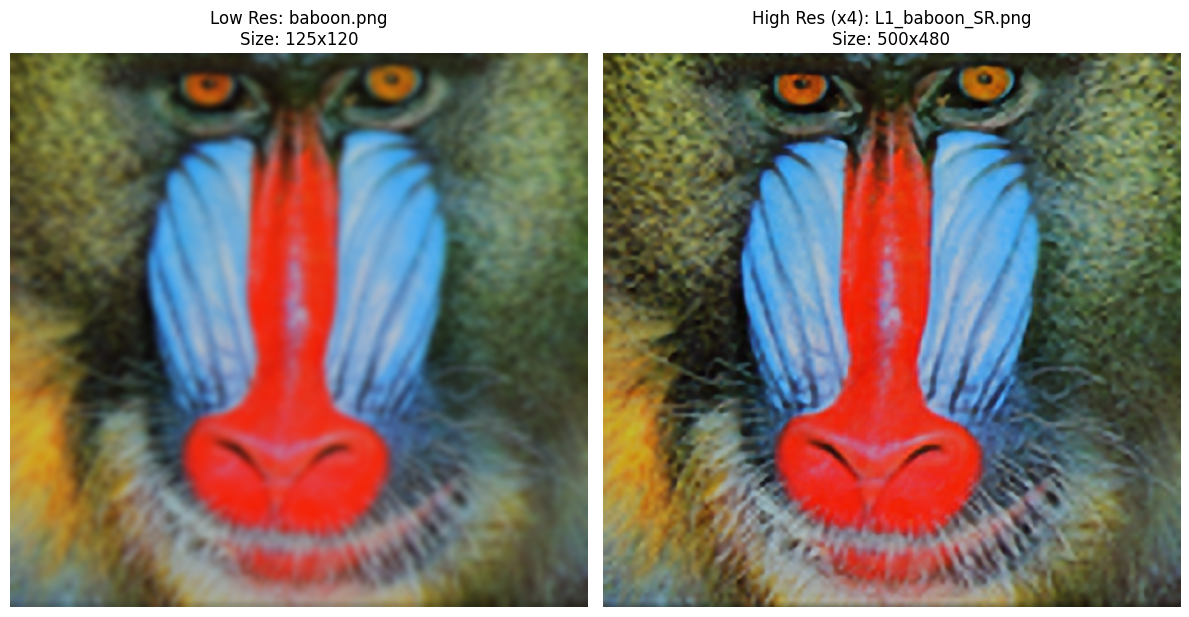

In [ ]:
path1 = "/content/test_images/baboon.png"
path2 = "/content/esrgan_l1_val/L1_baboon_SR.png"

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))


axes[0].imshow(img1,interpolation='bicubic')
axes[0].set_title(f"Low Res: {os.path.basename(path1)}\nSize: {img1.shape[1]}x{img1.shape[0]}", fontsize=12)
axes[0].axis('off')


axes[1].imshow(img2)
axes[1].set_title(f"High Res (x4): {os.path.basename(path2)}\nSize: {img2.shape[1]}x{img2.shape[0]}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 3.7-ESRGAN Training

In [ ]:
CHECKPOINT_GEN_esrgan_WARMUP = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/warmup_gen.pth.tar"


esrgan_gen = Generator_esrgan(in_channels=3).to(DEVICE)
esrgan_disc = Discriminator_esrgan(in_channels=3).to(DEVICE)


opt_gen_esrgan = optim.Adam(
    esrgan_gen.parameters(),
    lr=LEARNING_RATE,
    betas=(0.0, 0.9)
)

opt_disc_esrgan = optim.Adam(
    esrgan_disc.parameters(),
    lr=LEARNING_RATE,
    betas=(0.0, 0.9)
)


if os.path.exists(CHECKPOINT_GEN_esrgan_WARMUP):
    load_checkpoint_esrgan(
        CHECKPOINT_GEN_esrgan_WARMUP,
        esrgan_gen,
        opt_gen_esrgan,
        LEARNING_RATE,
        device=DEVICE
    )
    print("ESRGAN Warm-up Generator loaded successfully.")
    print("ESRGAN Discriminator starts from scratch.")
else:
    print(f"Warm-up checkpoint not found: {CHECKPOINT_GEN_esrgan_WARMUP}")

LOADED_STAGE = "warmup"

In [ ]:
CHECKPOINT_GEN_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_gen.pth.tar"
CHECKPOINT_DISC_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_disc.pth.tar"


esrgan_gen = Generator_esrgan(in_channels=3).to(DEVICE)
esrgan_disc = Discriminator_esrgan(in_channels=3).to(DEVICE)


opt_gen_esrgan = optim.Adam(
    esrgan_gen.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)

opt_disc_esrgan = optim.Adam(
    esrgan_disc.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999)
)


if os.path.exists(CHECKPOINT_GEN_ESRGAN):
    load_checkpoint_esrgan(
        CHECKPOINT_GEN_ESRGAN,
        esrgan_gen,
        opt_gen_esrgan,
        LEARNING_RATE,
        device=DEVICE
    )
    print("ESRGAN Generator loaded successfully.")
else:
    print("Generator checkpoint not found! Initializing from scratch.")

if os.path.exists(CHECKPOINT_DISC_ESRGAN):
    load_checkpoint_esrgan(
        CHECKPOINT_DISC_ESRGAN,
        esrgan_disc,
        opt_disc_esrgan,
        LEARNING_RATE,
        device=DEVICE
    )
    print("ESRGAN Discriminator loaded successfully.")
else:
    print("Discriminator checkpoint not found Initializing from scratch.")

LOADED_STAGE = "esrgan"
print("Ready to start ESRGAN training.")

=> Loading checkpoint
ESRGAN Generator loaded successfully.
=> Loading checkpoint
ESRGAN Discriminator loaded successfully.
Ready to start ESRGAN training.


In [ ]:
# tp step , writer >> tensor board
def train_fn_esrgan(
    loader,
    disc,
    gen,
    opt_gen,
    opt_disc,
    l1,
    vgg_loss,
    bce,
    g_scaler,
    d_scaler,
    writer,
    tb_step,
):
    loop = tqdm(loader, leave=True)


    running_critic = 0.0
    running_gen = 0.0
    running_l1 = 0.0
    running_vgg = 0.0
    running_adv = 0.0

    for idx, (low_res, high_res) in enumerate(loop):
        high_res = high_res.to(DEVICE)
        low_res = low_res.to(DEVICE)

        # ==========================================
        # 1. Train Discriminator (RaGAN)
        # ==========================================
        with torch.amp.autocast('cuda'):

            fake = gen(low_res)

            # Disc Predections
            critic_real = disc(high_res)
            critic_fake = disc(fake.detach())

            #Compute Losses
            loss_critic_real = bce(
                critic_real - critic_fake.mean(), torch.ones_like(critic_real)
            )

            loss_critic_fake = bce(
                critic_fake - critic_real.mean(), torch.zeros_like(critic_fake)
            )

            loss_critic = (loss_critic_real + loss_critic_fake) / 2

        opt_disc.zero_grad()
        d_scaler.scale(loss_critic).backward()
        d_scaler.step(opt_disc)
        d_scaler.update()

        # ==========================================
        # 2. Train Generator (RaGAN)
        # ==========================================
        with torch.amp.autocast('cuda'):

            # Disc Predections
            critic_fake_gen = disc(fake)
            critic_real_gen = critic_real.detach()

            # ADV Loss
            loss_gen_real = bce(
                critic_real_gen - critic_fake_gen.mean(), torch.zeros_like(critic_real_gen)
            )

            loss_gen_fake = bce(
                critic_fake_gen - critic_real_gen.mean(), torch.ones_like(critic_fake_gen)
            )
            adversarial_loss = 5e-3 * ((loss_gen_real + loss_gen_fake) / 2)

            # L1 Loss
            l1_loss = 1e-2 * l1(fake, high_res)
            #VGG Loss
            loss_for_vgg = vgg_loss(fake, high_res)

            gen_loss = l1_loss + loss_for_vgg + adversarial_loss

        opt_gen.zero_grad()
        g_scaler.scale(gen_loss).backward()
        g_scaler.step(opt_gen)
        g_scaler.update()


        running_critic += loss_critic.item()
        running_gen += gen_loss.item()
        running_l1 += l1_loss.item()
        running_vgg += loss_for_vgg.item()
        running_adv += adversarial_loss.item()

        writer.add_scalar("Critic loss", loss_critic.item(), global_step=tb_step)
        writer.add_scalar("Gen loss", gen_loss.item(), global_step=tb_step)
        tb_step += 1

        loop.set_postfix(
            critic=loss_critic.item(),
            l1=l1_loss.item(),
            vgg=loss_for_vgg.item(),
            adv=adversarial_loss.item(),
        )


    num_batches = len(loader)
    avg_losses = {
        "critic": running_critic / num_batches,
        "gen": running_gen / num_batches,
        "l1": running_l1 / num_batches,
        "vgg": running_vgg / num_batches,
        "adv": running_adv / num_batches,
    }

    return tb_step, avg_losses

# =====================================================
# Main
# =====================================================
def main():
    required_objects = ["esrgan_gen","esrgan_disc","opt_gen_esrgan","opt_disc_esrgan",]

    missing_objects = [
        name for name in required_objects if name not in globals()
    ]

    if missing_objects:
        raise RuntimeError(
            "Run the loading cell first. Missing objects: "
            + ", ".join(missing_objects)
        )

    print("ESRGAN Generator object found.")
    print("ESRGAN Discriminator object found.")
    print("ESRGAN Generator optimizer found.")
    print("ESRGAN Discriminator optimizer found.")

    if "LOADED_STAGE" not in globals():
        raise RuntimeError("Run the loading cell first to define LOADED_STAGE.")

    print(f"\n========== {LOADED_STAGE.upper()} ==========\n")

    train_path = "/content/DIV2K_train_HR/DIV2K_train_HR"

    CHECKPOINT_GEN_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_gen.pth.tar"
    CHECKPOINT_DISC_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_disc.pth.tar"

    dataset = MyImageFolder_esrgan(root_dir=train_path)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=torch.cuda.is_available(),
        num_workers=NUM_WORKERS,
    )

    l1 = nn.L1Loss()
    bce = nn.BCEWithLogitsLoss().to(DEVICE)
    vgg_loss = VGGLoss_esrgan().to(DEVICE)

    writer = SummaryWriter("logs")
    tb_step = 0

    g_scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None
    d_scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

    esrgan_gen.train()
    esrgan_disc.train()

    print(f"Starting ESRGAN Relativistic training for {NUM_EPOCHS} epochs...")

    for epoch in range(NUM_EPOCHS):
        print(f"\n--- ESRGAN Epoch [{epoch + 1}/{NUM_EPOCHS}] ---")

        tb_step, avg_losses = train_fn_esrgan(
            loader=loader,
            disc=esrgan_disc,
            gen=esrgan_gen,
            opt_gen=opt_gen_esrgan,
            opt_disc=opt_disc_esrgan,
            l1=l1,
            vgg_loss=vgg_loss,
            bce=bce,
            g_scaler=g_scaler,
            d_scaler=d_scaler,
            writer=writer,
            tb_step=tb_step,
        )

        print(
            f"\n [Epoch {epoch + 1} Averages] "
            f"Gen: {avg_losses['gen']:.4f} | "
            f"Critic: {avg_losses['critic']:.4f} | "
            f"L1: {avg_losses['l1']:.4f} | "
            f"VGG: {avg_losses['vgg']:.4f} | "
            f"Adv: {avg_losses['adv']:.4f}"
        )


        esrgan_gen.eval()
        plot_examples_esrgan(esrgan_gen)
        esrgan_gen.train()


        if SAVE_MODEL:
            save_checkpoint_esrgan(
                model=esrgan_gen,
                optimizer=opt_gen_esrgan,
                filename=CHECKPOINT_GEN_ESRGAN
            )

            save_checkpoint_esrgan(
                model=esrgan_disc,
                optimizer=opt_disc_esrgan,
                filename=CHECKPOINT_DISC_ESRGAN
            )


if __name__ == "__main__":
    main()

In [ ]:
CHECKPOINT_GEN_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/esrgan_gen.pth.tar"

esrgan_gen = Generator_esrgan(in_channels=3).to(DEVICE)

if os.path.exists(CHECKPOINT_GEN_ESRGAN):
    load_model_weights_esrgan(CHECKPOINT_GEN_ESRGAN, esrgan_gen, DEVICE)
    LOADED_STAGE = "esrgan"
    esrgan_gen.eval()
    print("ESRGAN Generator ready for inference.")
else:
    print(f"Checkpoint not found: {CHECKPOINT_GEN_ESRGAN}")

=> Loading ESRGAN model for inference...
=> ESRGAN model loaded successfully.
ESRGAN Generator ready for inference.


In [ ]:
# ==========================================
# Validation on test_images (ESRGAN)
# ==========================================

test_folder = "test_images"
output_folder = "esrgan_val"

os.makedirs(output_folder, exist_ok=True)

esrgan_gen.eval()

with torch.no_grad():

    files = sorted(os.listdir(test_folder))

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)


        image = (
            test_transform_esrgan(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE)
        )

        sr = esrgan_gen(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)


        save_image(
            sr.clamp(0, 1),
            os.path.join(
                output_folder,
                f"ESRGAN_{name}_SR{ext}"
            )
        )

esrgan_gen.train()

print(f"Finished Results saved in '{output_folder}'")

Finished Results saved in 'esrgan_val'


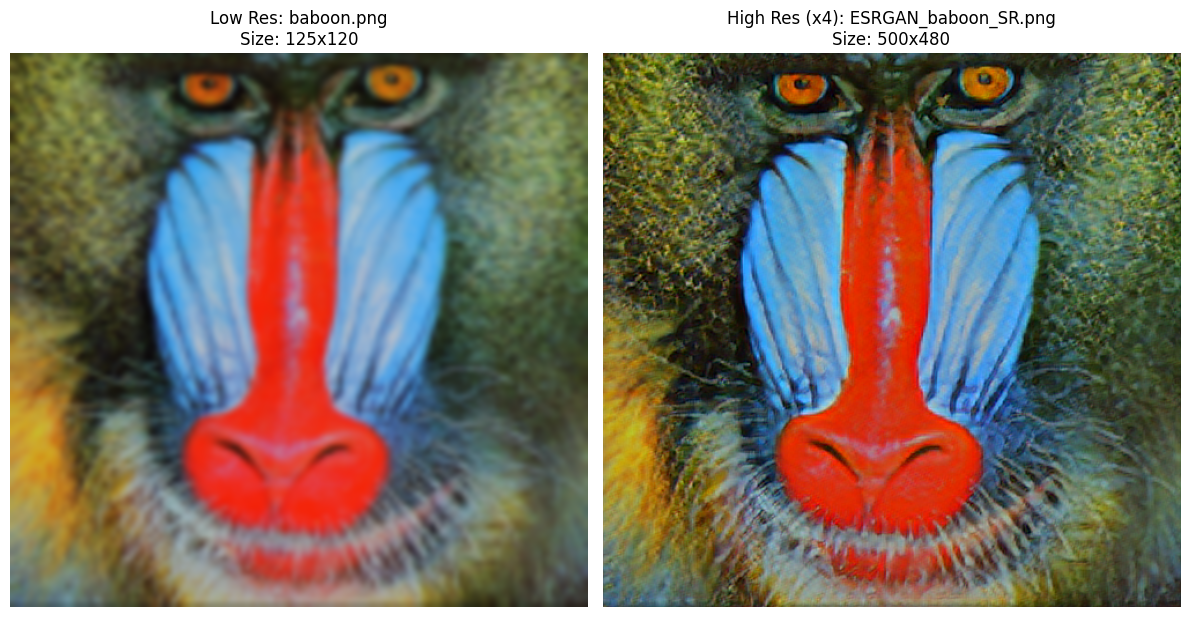

In [ ]:
path1 = "/content/test_images/baboon.png"
path2 = "/content/esrgan_val/ESRGAN_baboon_SR.png"

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))


axes[0].imshow(img1,interpolation='bicubic')
axes[0].set_title(f"Low Res: {os.path.basename(path1)}\nSize: {img1.shape[1]}x{img1.shape[0]}", fontsize=12)
axes[0].axis('off')


axes[1].imshow(img2)
axes[1].set_title(f"High Res (x4): {os.path.basename(path2)}\nSize: {img2.shape[1]}x{img2.shape[0]}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# (4)-Results and Measurements

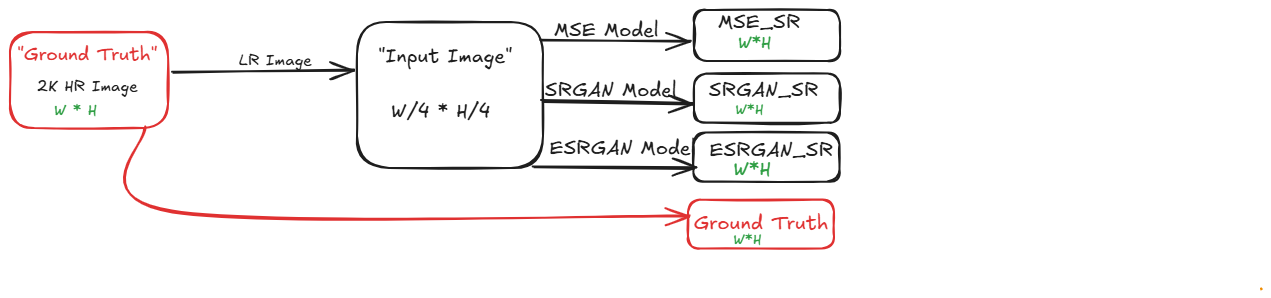

In [ ]:
display(IPImage("/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/images/Comparison.png", width=1000))

### 4.1-Preparing Images

In [ ]:
##############################################################################################################
#                                   CREATE "LR" COPIES
##############################################################################################################

input_folder = "/content/inference_images"
output_folder = "/content/LR_inference_images"

os.makedirs(output_folder, exist_ok=True)

image_names = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))]

print(f"=> {len(image_names)} Images Are Found")


for img_name in image_names:
    img_path = os.path.join(input_folder, img_name)

    img = cv2.imread(img_path)
    if img is None:
        continue

    height, width = img.shape[:2]
    new_width = width // 4
    new_height = height // 4

    resized_img = cv2.resize(img, (new_width, new_height), interpolation=cv2.INTER_CUBIC)

    filename, ext = os.path.splitext(img_name)
    new_filename = f"LR_{filename}{ext}"


    save_path = os.path.join(output_folder, new_filename)
    cv2.imwrite(save_path, resized_img)
print("Saved successfully")

=> 10 Images Are Found
Saved successfully


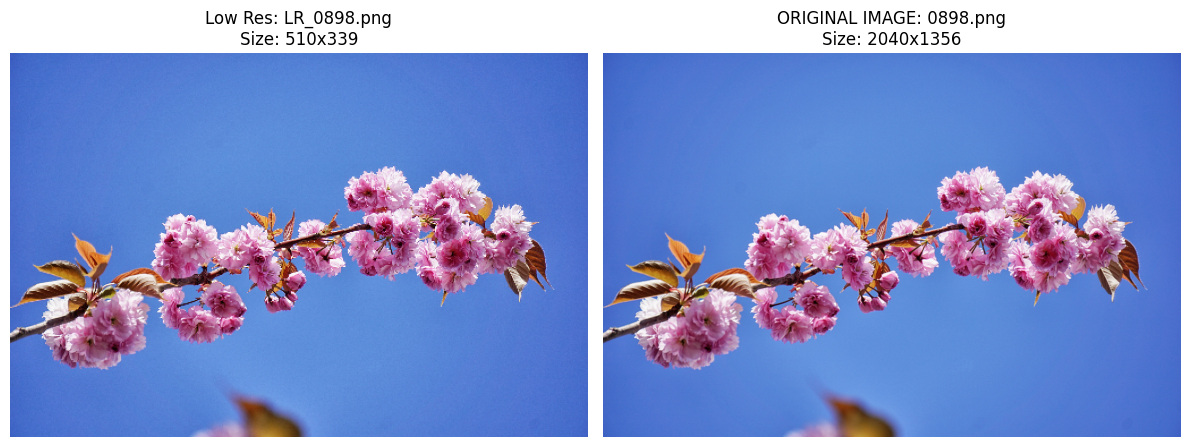

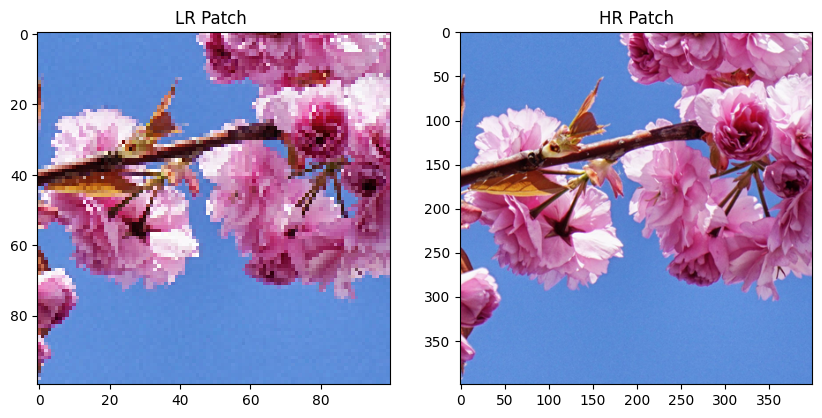

In [ ]:
path1 = "/content/LR_inference_images/LR_0898.png"
path2 = "/content/inference_images/0898.png"

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))


axes[0].imshow(img1)
axes[0].set_title(f"Low Res: {os.path.basename(path1)}\nSize: {img1.shape[1]}x{img1.shape[0]}", fontsize=12)
axes[0].axis('off')


axes[1].imshow(img2)
axes[1].set_title(f"ORIGINAL IMAGE: {os.path.basename(path2)}\nSize: {img2.shape[1]}x{img2.shape[0]}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

#SMALL BATCH
patch_lr = img1[125:225, 250:350]
patch_hr = img2[500:900, 1000:1400]


fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(patch_lr)
ax[0].set_title("LR Patch ")

ax[1].imshow(patch_hr)
ax[1].set_title("HR Patch")
plt.show()

In [ ]:
##############################################################################################################
#                                   CREATE "MSE" COPIES
##############################################################################################################
test_folder = "LR_inference_images"
output_folder = "MSE_inference_images"

os.makedirs(output_folder, exist_ok=True)

files = sorted(os.listdir(test_folder))

print(f"Found {len(files)} file(s) inside {test_folder}")

saved_count = 0

with torch.no_grad():

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(test_folder, file)

        image = Image.open(image_path).convert("RGB")
        image = np.asarray(image)

        image = (
            test_transform(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE))


        sr = mse_gen_test(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)

        output_path = os.path.join(
            output_folder,
            f"MSE_{name}_SR{ext}"
        )

        save_image(
            (sr * 0.5 + 0.5).clamp(0, 1),
            output_path)

        print(f"Saved: {output_path} ")

        saved_count += 1


print(f"Finished Results saved in '{output_folder}'")
print("="*60)

##############################################################################################################
#                                   CREATE "SRGAN" COPIES
##############################################################################################################
test_folder = "LR_inference_images"
output_folder = "SRGAN_inference_images"

os.makedirs(output_folder, exist_ok=True)

srgan_gen_test.eval()

with torch.no_grad():

    files = sorted(os.listdir(test_folder))

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)

        image = (
            test_transform(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE))

        sr = srgan_gen_test(image)

        name, ext = os.path.splitext(file)

        name = name.replace("lr_", "", 1)

        save_image((sr * 0.5 + 0.5).clamp(0, 1),os.path.join(output_folder,f"SRGAN_{name}_SR{ext}"))

srgan_gen_test.train()

print(f"Finished Results saved in '{output_folder}'")
print("="*60)
##############################################################################################################
#                                   CREATE "ESRGAN" COPIES
##############################################################################################################
test_folder = "LR_inference_images"
output_folder = "ESRGAN_inference_images"

os.makedirs(output_folder, exist_ok=True)

esrgan_gen.eval()

with torch.no_grad():

    files = sorted(os.listdir(test_folder))

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)


        image = (
            test_transform_esrgan(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE)
        )

        sr = esrgan_gen(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)


        save_image(
            sr.clamp(0, 1),
            os.path.join(
                output_folder,
                f"ESRGAN_{name}_SR{ext}"
            )
        )

esrgan_gen.train()

print(f"Finished Results saved in '{output_folder}'")
print("="*60)
##############################################################################################################
#                                   CREATE "Full ESRGAN" COPIES
##############################################################################################################
CHECKPOINT_GEN_full_ESRGAN = "/content/drive/MyDrive/Colab Notebooks/DL_PROJECT/fULL_esrgan_gen.pth.tar"

full_esrgan_gen = Generator_esrgan(in_channels=3).to(DEVICE)

if os.path.exists(CHECKPOINT_GEN_ESRGAN):
    load_model_weights_esrgan(CHECKPOINT_GEN_full_ESRGAN, full_esrgan_gen, DEVICE)
    LOADED_STAGE = "esrgan"
    full_esrgan_gen.eval()
    print("Full ESRGAN Generator ready for inference.")
else:
    print(f"Checkpoint not found: {CHECKPOINT_GEN_full_ESRGAN}")


test_folder = "LR_inference_images"
output_folder = "Full_SRGAN_inference_images"

os.makedirs(output_folder, exist_ok=True)

full_esrgan_gen.eval()

with torch.no_grad():

    files = sorted(os.listdir(test_folder))

    for file in files:

        if not file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif")):
            continue

        image = Image.open(os.path.join(test_folder, file)).convert("RGB")
        image = np.asarray(image)


        image = (
            test_transform_esrgan(image=image)["image"]
            .unsqueeze(0)
            .to(DEVICE)
        )

        sr = full_esrgan_gen(image)

        name, ext = os.path.splitext(file)
        name = name.replace("lr_", "", 1)


        save_image(
            sr.clamp(0, 1),
            os.path.join(
                output_folder,
                f"Full_ESRGAN_{name}_SR{ext}"
            )
        )

full_esrgan_gen.train()

print(f"Finished Results saved in '{output_folder}'")

Found 10 file(s) inside LR_inference_images
Saved: MSE_inference_images/MSE_LR_0801_SR.png 
Saved: MSE_inference_images/MSE_LR_0803_SR.png 
Saved: MSE_inference_images/MSE_LR_0815_SR.png 
Saved: MSE_inference_images/MSE_LR_0831_SR.png 
Saved: MSE_inference_images/MSE_LR_0846_SR.png 
Saved: MSE_inference_images/MSE_LR_0853_SR.png 
Saved: MSE_inference_images/MSE_LR_0884_SR.png 
Saved: MSE_inference_images/MSE_LR_0898_SR.png 
Saved: MSE_inference_images/MSE_LR_0899_SR.png 
Saved: MSE_inference_images/MSE_LR_0900_SR.png 
Finished Results saved in 'MSE_inference_images'
Finished Results saved in 'SRGAN_inference_images'
Finished Results saved in 'ESRGAN_inference_images'
=> Loading ESRGAN model for inference...
=> ESRGAN model loaded successfully.
Full ESRGAN Generator ready for inference.
Finished Results saved in 'Full_SRGAN_inference_images'


### 4.2-Result

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt


path_gt          = "/content/inference_images/0801.png"
path_lr          = "/content/LR_inference_images/LR_0801.png"
path_mse         = "/content/MSE_inference_images/MSE_LR_0801_SR.png"
path_srgan       = "/content/SRGAN_inference_images/SRGAN_LR_0801_SR.png"
path_esrgan      = "/content/ESRGAN_inference_images/ESRGAN_LR_0801_SR.png"
path_full_esrgan = "/content/Full_SRGAN_inference_images/Full_ESRGAN_LR_0801_SR.png"


img_gt          = cv2.cvtColor(cv2.imread(path_gt), cv2.COLOR_BGR2RGB)
img_lr          = cv2.cvtColor(cv2.imread(path_lr), cv2.COLOR_BGR2RGB)
img_mse         = cv2.cvtColor(cv2.imread(path_mse), cv2.COLOR_BGR2RGB)
img_srgan       = cv2.cvtColor(cv2.imread(path_srgan), cv2.COLOR_BGR2RGB)
img_esrgan      = cv2.cvtColor(cv2.imread(path_esrgan), cv2.COLOR_BGR2RGB)
img_full_esrgan = cv2.cvtColor(cv2.imread(path_full_esrgan), cv2.COLOR_BGR2RGB)


h, w, _ = img_gt.shape
img_bicubic = cv2.resize(img_lr, (w, h), interpolation=cv2.INTER_CUBIC)


full_images = [img_gt, img_bicubic, img_mse, img_srgan, img_esrgan, img_full_esrgan]
titles      = [
    "Ground Truth",
    "Bicubic Upscaled",
    "MSE Model",
    "SRGAN Model",
    "ESRGAN Model",
    "Full ESRGAN"
]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()

for i in range(6):
    axes_flat[i].imshow(full_images[i])
    axes_flat[i].set_title(f"{titles[i]}\nSize: {full_images[i].shape[1]}x{full_images[i].shape[0]}", fontsize=12)
    axes_flat[i].axis('off')

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
y_start_hr, y_end_hr = 200, 600
x_start_hr, x_end_hr = 700, 1100

patch_gt          = img_gt[y_start_hr:y_end_hr, x_start_hr:x_end_hr]
patch_bicubic     = img_bicubic[y_start_hr:y_end_hr, x_start_hr:x_end_hr]
patch_mse         = img_mse[y_start_hr:y_end_hr, x_start_hr:x_end_hr]
patch_srgan       = img_srgan[y_start_hr:y_end_hr, x_start_hr:x_end_hr]
patch_esrgan      = img_esrgan[y_start_hr:y_end_hr, x_start_hr:x_end_hr]
patch_full_esrgan = img_full_esrgan[y_start_hr:y_end_hr, x_start_hr:x_end_hr]

patches = [
    patch_gt,
    patch_bicubic,
    patch_mse,
    patch_srgan,
    patch_esrgan,
    patch_full_esrgan
]

titles = [
    "Ground Truth Patch",
    "Bicubic Patch",
    "MSE Patch",
    "SRGAN Patch",
    "ESRGAN Patch",
    "Full ESRGAN Patch"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes_flat = axes.flatten()

for i in range(6):
    axes_flat[i].imshow(patches[i])
    axes_flat[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes_flat[i].axis('off')

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

### 4.3-PSNR

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr

folders = {
    "MSE Model": "/content/MSE_inference_images",
    "SRGAN Model": "/content/SRGAN_inference_images",
    "ESRGAN Model": "/content/ESRGAN_inference_images",
    "Full ESRGAN Model": "/content/Full_SRGAN_inference_images"
}

gt_folder = "/content/inference_images"


gt_images = sorted([f for f in os.listdir(gt_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])[:10]

psnr_results = {model_name: [] for model_name in folders.keys()}

for img_name in gt_images:
    gt_path = os.path.join(gt_folder, img_name)
    img_gt = cv2.imread(gt_path)
    if img_gt is None:
        continue

    img_id = os.path.splitext(img_name)[0]

    for model_name, folder_path in folders.items():

        matching_file = None
        for f in os.listdir(folder_path):
            if img_id in f and f.lower().endswith(('.png', '.jpg', '.jpeg')):
                matching_file = f
                break

        if matching_file:
            pred_path = os.path.join(folder_path, matching_file)
            img_pred = cv2.imread(pred_path)


            if img_pred is not None and img_gt.shape == img_pred.shape:
                score = psnr(img_gt, img_pred, data_range=255)
                psnr_results[model_name].append(score)


print("=" * 55)
print(f"       Average PSNR Evaluation Across ({len(gt_images)}) Images       ")
print("=" * 55)

for model_name, scores in psnr_results.items():
    if scores:
        avg_psnr = np.mean(scores)
        print(f"{model_name:<20} : {avg_psnr:.2f} dB  (Evaluated on {len(scores)} images)")
    else:
        print(f"{model_name:<20} : No matching images found")

print("=" * 55)

       Average PSNR Evaluation Across (10) Images       
MSE Model            : 25.45 dB  (Evaluated on 10 images)
SRGAN Model          : 25.57 dB  (Evaluated on 10 images)
ESRGAN Model         : 21.69 dB  (Evaluated on 10 images)
Full ESRGAN Model    : 17.35 dB  (Evaluated on 10 images)


# (5)-Conclusion

**Conclusion & Summary of Results**

In this study, we evaluated and compared four Super-Resolution approaches:
1. **MSE-based Baseline Model**
2. **SRGAN Model**
3. **ESRGAN Model**
4. **Full ESRGAN Model**

---

**Quantitative Evaluation vs. Visual Perception**

Our quantitative evaluation across **PSNR** metrix revealed a classic **Perceptual-Distortion Trade-off**:

* **Pixel-wise Models (Highest PSNR):**
  The **SRGAN** model achieved the highest PSNR (**25.57 dB**), closely followed by the **MSE-based model** (**25.45 dB**). The MSE model directly minimizes pixel-wise reconstruction error, while the warm-up stage of SRGAN preserves this objective, resulting in similarly high quantitative performance.

* **ESRGAN-based Models (Perceptual Optimization):**
  The **ESRGAN** (**21.69 dB**) and **Full ESRGAN** (**17.35 dB**) models achieved lower PSNR values. This reduction is expected because these models optimize perceptual realism rather than pixel-wise similarity. Their adversarial and perceptual losses encourage the synthesis of sharper textures and more realistic high-frequency details, which often introduce slight spatial or intensity differences that are heavily penalized by pixel-based metrics such as PSNR.
---

**Key Takeaway**

Visual assessment confirms that **ESRGAN-based architectures produce superior, sharper, and more photorealistic images for human perception**, despite lower conventional metrics.

> **Conclusion:** Standard PSNR and Other Quantitive metrics are insufficient on their own for evaluating modern generative models.

**References**

**Theoretical References (Research Papers)**
1. **SRGAN Paper:**  
   Ledig, C., Theis, L., Huszár, F., Caballero, J., Cunningham, A., Acosta, A., Aitken, A., Tejani, A., Totz, J., Wang, Z., & Shi, W. (2017). *Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network*. IEEE Conference on Computer Vision and Pattern Recognition (CVPR).  
   🔗 [arXiv:1609.04802](https://arxiv.org/abs/1609.04802)

2. **ESRGAN Paper:**  
   Wang, X., Yu, K., Wu, S., Gu, J., Liu, Y., Dong, C., Qiao, Y., & Loy, C. C. (2018). *ESRGAN: Enhanced Super-Resolution Generative Adversarial Networks*. European Conference on Computer Vision (ECCV) Workshops.  
   🔗 [arXiv:1809.00219](https://arxiv.org/abs/1809.00219)

---

**Practical & Implementation References**
1. **PyTorch SRGAN Codebase:**  
   Persson, A. *SRGAN Implementation in PyTorch*. Machine Learning Collection Repository.  
   🔗 [GitHub: Aladdinpersson / SRGAN](https://github.com/aladdinpersson/Machine-Learning-Collection/tree/master/ML/Pytorch/GANs/SRGAN)

2. **PyTorch ESRGAN Codebase:**  
   Persson, A. *ESRGAN Implementation in PyTorch*. Machine Learning Collection Repository.  
   🔗 [GitHub: Aladdinpersson / ESRGAN](https://github.com/aladdinpersson/Machine-Learning-Collection/tree/master/ML/Pytorch/GANs/ESRGAN)